# Figure 6 — Greenberg–Hastings spiral

This notebook reproduces Figure 6 of *Statistical asymmetry: an entropic
measure of symmetry*. It evolves a 100 × 100 grid for 100 steps under
the Greenberg–Hastings model with periodic boundaries. The initial
configuration is quiescent except for two adjacent half-lines of
excited and refractory cells extending from the centre to the right.

The left panels show statistical asymmetry under translations,
reflections, and quarter-turn rotations. The right panels show the
grid at steps 0, 50, and 100. The notebook also prints the number of
cells in each state at those three steps.

See the README errata for the corrections to the published caption.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

In [2]:
def hamming(x, y):
    return np.count_nonzero(x!=y)   

def h_translations(array):
    
    x = np.asarray(array)
    m = len(x)//2 + 1
    k = np.zeros(m)
    
    for i in range(m):
        ss = np.roll(x, i, axis=1)
        k[i] = hamming(x, ss)

    return k, m

def v_translations(array):
    
    x = np.asarray(array)
    m = len(x)//2 + 1
    k = np.zeros(m)
    
    for i in range(m):
        ss = np.roll(x, i, axis=0)
        k[i] = hamming(x, ss)

    return k, m
    
def v_reflections(array):
    
    x = np.asarray(array)
    y = np.transpose(x)
    y = y[::-1]
    y = np.transpose(y)
    
    return np.asarray([0, hamming(x,y)]), 2
    
def h_reflections(array):
    
    x = np.asarray(array)
    y = x[::-1]
    
    return np.asarray([0, hamming(x,y)]), 2
    
def rotations(array):
    
    x = np.asarray(array)
    k = np.zeros(4)
    ss = x
    
    for i in range(4):
        ss = np.rot90(ss)
        k[i] = hamming(x, ss)
        
    return k, 4

def disc_dist(sequence):
    
    d = set(sequence)
    m = len(d)
    
    pk = np.zeros(m)
    for i in range(m):
        pk[i] = list(sequence).count(list(d)[i])
    
    return pk/sum(pk)

# Scaled by maximum distance
def sA(x, group):
    s = group(x)
    d1 = s[0]
    p1 = disc_dist(d1)
    n1 = s[1]
    e1 = entropy(p1)/np.log(n1)
    
    return e1*np.max(d1)/len(x.flatten())

# Greenberg-Hastings Grid Update
def ghm(grid):
    new_grid = np.copy(grid)
    for i in range(N):
        for j in range(N):
            if grid[i, j] == 0:  # Excitable state
                # Check if any neighbor is excited
                neighbors = [
                    grid[(i-1)%N, j], grid[(i+1)%N, j],
                    grid[i, (j-1)%N], grid[i, (j+1)%N]
                ]
                if 1 in neighbors:
                    new_grid[i, j] = 1  # Become excited
            elif grid[i, j] == 1:  # Excited state
                new_grid[i, j] = 2  # Become refractory
            elif grid[i, j] == 2:  # Refractory state
                new_grid[i, j] = 0  # Become excitable again
    return new_grid

# GHM Spiral Initial State
def spiral(nside):
    sgrid = np.zeros((nside,nside))
    sgrid[nside//2, nside//2:] = 1
    sgrid[nside//2+1, nside//2:] = 2
    
    return sgrid

t =   0: [9900, 50, 50]
t =  50: [6150, 1950, 1900]
t = 100: [5002, 2498, 2500]


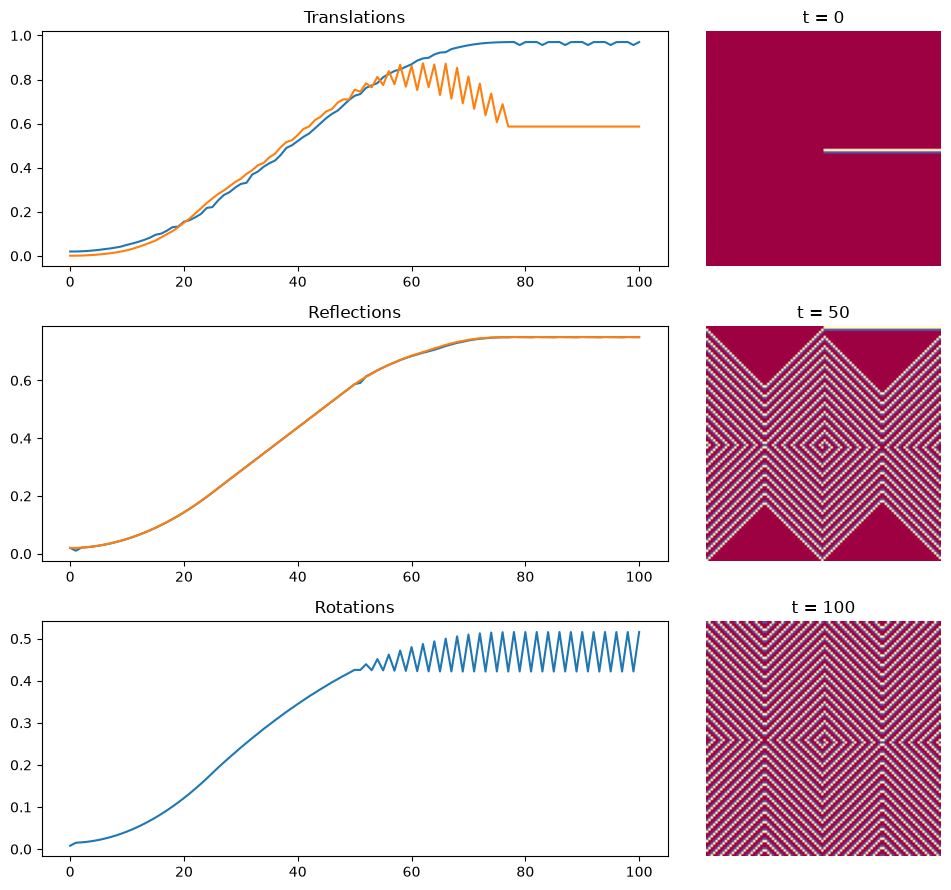

In [3]:
N = 100  # The original ghm function uses this grid size.
frames = (0, 50, 100)
snapshots = {}
groups = (
    h_translations, v_translations,
    h_reflections, v_reflections,
    rotations,
)
asymmetry = np.empty((101, len(groups)))

grid = spiral(N)
for time in range(101):
    asymmetry[time] = [sA(grid, group) for group in groups]
    if time in frames:
        snapshots[time] = grid.copy()
    if time < 100:
        grid = ghm(grid)

fig, axes = plt.subplots(3, 2, figsize=(10, 9), width_ratios=(2, 1))
for row, title, columns in (
    (0, "Translations", (0, 1)),
    (1, "Reflections", (2, 3)),
    (2, "Rotations", (4,)),
):
    axes[row, 0].plot(asymmetry[:, columns])
    axes[row, 0].set_title(title)

for ax, time in zip(axes[:, 1], frames):
    ax.imshow(snapshots[time], cmap="Spectral", vmin=0, vmax=2)
    ax.set_title(f"t = {time}")
    ax.set_axis_off()
    counts = np.bincount(snapshots[time].astype(int).ravel(), minlength=3)
    print(f"t = {time:3d}: {counts.tolist()}")

fig.tight_layout()
plt.show()